# Hierarchical EEGNet — EEG Artifact Classification

Leave-one-subject-out (LOSO) EEGNet pipeline operating on the **raw EEG windows**
in `windows_raw.pkl` (no handcrafted features). The label hierarchy mirrors
`03_RandomForest.ipynb` and `04_XGBoost.ipynb`:

1. **Stage 1** — artifact vs rest
2. **Stage 2** — ocular vs head_muscle
3. **Stage 3a / 3b** — fine label within each coarse group

Each stage is a freshly trained EEGNet (Lawhern et al., 2018) with a global
**max**-pooling head, focal loss, and per-layer max-norm constraints. A chained
end-to-end pipeline (Stage 1 → 2 → 3a/3b) is evaluated against the 7-class fine
vocabulary and compared with the Random-Forest and XGBoost chained baselines.

The fold logic, stage filtering, accumulator pattern, and evaluation sections
follow `03_RandomForest.ipynb`.

## Device

Google Colab with a CUDA GPU is the intended run environment; the cell falls
back to Apple MPS and then CPU so the notebook also runs locally.

In [1]:
import torch

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Torch Version:", torch.__version__)
print(f"Device: {device}")

Torch Version: 2.5.1+cu121
Device: cuda


## Section 1 — Imports & configuration

In [2]:
import pickle
import random
import time
from collections import defaultdict
from copy import deepcopy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix, classification_report,
    roc_auc_score,
)

CONFIG = {
    "DATA_DIR":      Path("processed_xdf"),
    "OUTPUT_DIR":    Path("processed_xdf/05_EEGNet_plots"),
    "SFREQ":         250,
    "N_CHANNELS":    4,
    "N_SAMPLES":     500,
    "F1":            8,      # temporal filters
    "D":             2,      # spatial depth multiplier -> F1*D=16 spatial filters
    "F2":            16,     # separable filters
    "KERNEL_T":      63,     # temporal kernel: 252ms at 250Hz, compromise between
                             # slow EEG waves and fast EMG bursts (99Hz content)
    "DROPOUT":       0.25,
    "BATCH_SIZE":    64,
    "LR":            1e-3,
    "WEIGHT_DECAY":  1e-4,
    "MAX_EPOCHS":    150,
    "PATIENCE_ES":   15,     # early stopping
    "PATIENCE_LR":   10,     # ReduceLROnPlateau
    "LR_FACTOR":     0.3,
    "VAL_SPLIT":     0.2,
    "FOCAL_GAMMA":   2.0,
    "NORM_DEPTHWISE": 1.0,   # max norm on depthwise conv
    "NORM_LINEAR":    0.25,  # max norm on final linear layer
    "RANDOM_STATE":  42,
    # Thresholding baseline results (from 02_Thresholding.ipynb) for comparison.
    "THRESHOLDING_ACC": 0.7759,
    "THRESHOLDING_F1":  0.7706,
    # Random Forest chained results (from 03_RandomForest.ipynb) for comparison.
    "RF_CHAINED_ACC":   0.7259,
    "RF_CHAINED_F1":    0.6196,
    # XGBoost chained results (from 04_XGBoost.ipynb) for comparison.
    "XGB_CHAINED_ACC":  0.7499,
    "XGB_CHAINED_F1":   0.6576
}

# Exact label sets each stage is allowed to see and predict.
STAGE2_LABELS  = ("ocular", "head_muscle")
STAGE3A_LABELS = ("blink", "look_left", "look_right")
STAGE3B_LABELS = ("horiz_head", "vert_head", "clench")

# ---- Reproducibility: fix every RNG ----
SEED = CONFIG["RANDOM_STATE"]
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)

CONFIG["OUTPUT_DIR"].mkdir(parents=True, exist_ok=True)
CONFIG["DATA_DIR"].mkdir(parents=True, exist_ok=True)
sns.set_context("notebook")
print("Configuration ready.")

Configuration ready.


## Section 2 — Model definition

EEGNet as a `torch.nn.Module`. Input shape `(batch, 1, 4, 500)` — one "image"
with height = channels and width = time samples.

The head uses **`AdaptiveMaxPool2d((1, 1))` (global max-pooling), not average
pooling**: max-pooling keeps the strongest activation anywhere in the window,
which matters for transient events (blinks, clench bursts) that occupy only a
fraction of the 2-second window. The classifier `in_features` is determined by a
dummy forward pass — nothing is hardcoded.

In [3]:
# Section 2 — EEGNet model.
class EEGNet(nn.Module):
    """EEGNet (Lawhern et al., 2018) with a global max-pooling head.

    Input  : (batch, 1, n_channels, n_samples)
    Output : (batch, n_classes) raw logits.
    """

    def __init__(self, n_channels: int, n_samples: int, n_classes: int,
                 config: dict):
        super().__init__()
        F1, D, F2 = config["F1"], config["D"], config["F2"]
        kt, drop = config["KERNEL_T"], config["DROPOUT"]

        # Block 1 — temporal conv (padding keeps the time axis length).
        self.conv_temporal = nn.Conv2d(
            1, F1, kernel_size=(1, kt), padding=(0, kt // 2), bias=False)
        self.bn1 = nn.BatchNorm2d(F1)

        # Block 1 — depthwise spatial conv (one group per temporal filter).
        self.conv_spatial = nn.Conv2d(
            F1, F1 * D, kernel_size=(n_channels, 1), groups=F1, bias=False)
        self.bn2 = nn.BatchNorm2d(F1 * D)
        self.pool1 = nn.AvgPool2d((1, 4))
        self.drop1 = nn.Dropout(drop)

        # Block 2 — separable conv (depthwise temporal + pointwise mix).
        self.conv_sep_depth = nn.Conv2d(
            F1 * D, F1 * D, kernel_size=(1, 16), padding=(0, 8),
            groups=F1 * D, bias=False)
        self.conv_sep_point = nn.Conv2d(F1 * D, F2, kernel_size=(1, 1), bias=False)
        self.bn3 = nn.BatchNorm2d(F2)
        self.pool2 = nn.AvgPool2d((1, 8))
        self.drop2 = nn.Dropout(drop)

        # Global MAX pooling head (not average) + flatten.
        self.global_pool = nn.AdaptiveMaxPool2d((1, 1))
        self.flatten = nn.Flatten()

        # Determine classifier in-features dynamically with a dummy forward.
        with torch.no_grad():
            dummy = torch.zeros(1, 1, n_channels, n_samples)
            in_features = self._features(dummy).shape[1]
        self.classifier = nn.Linear(in_features, n_classes)

    def _features(self, x: torch.Tensor) -> torch.Tensor:
        # Block 1.
        x = self.bn1(self.conv_temporal(x))
        x = F.elu(self.bn2(self.conv_spatial(x)))
        x = self.drop1(self.pool1(x))
        # Block 2.
        x = self.conv_sep_point(self.conv_sep_depth(x))
        x = F.elu(self.bn3(x))
        x = self.drop2(self.pool2(x))
        # Head.
        x = self.global_pool(x)
        return self.flatten(x)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self._features(x))


def apply_max_norm(model: nn.Module, config: dict) -> None:
    """Clamp depthwise-conv and final-linear weight norms after an optimiser step."""
    # Depthwise conv weights (any grouped conv).
    for module in model.modules():
        if isinstance(module, nn.Conv2d) and module.groups > 1:
            w = module.weight.data
            norm = w.norm(2, dim=(1, 2, 3), keepdim=True)
            w.data = w * (config["NORM_DEPTHWISE"] /
                          norm.clamp(min=config["NORM_DEPTHWISE"]))
    # Final linear layer.
    for module in model.modules():
        if isinstance(module, nn.Linear):
            w = module.weight.data
            norm = w.norm(2, dim=1, keepdim=True)
            w.data = w * (config["NORM_LINEAR"] /
                          norm.clamp(min=config["NORM_LINEAR"]))


# Architecture preview + parameter count (binary stage as example).
_preview = EEGNet(CONFIG["N_CHANNELS"], CONFIG["N_SAMPLES"], 2, CONFIG)
_n_params = sum(p.numel() for p in _preview.parameters() if p.requires_grad)
print(_preview)
print(f"\nTrainable parameters (n_classes=2): {_n_params:,}")
del _preview

EEGNet(
  (conv_temporal): Conv2d(1, 8, kernel_size=(1, 63), stride=(1, 1), padding=(0, 31), bias=False)
  (bn1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv_spatial): Conv2d(8, 16, kernel_size=(4, 1), stride=(1, 1), groups=8, bias=False)
  (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
  (drop1): Dropout(p=0.25, inplace=False)
  (conv_sep_depth): Conv2d(16, 16, kernel_size=(1, 16), stride=(1, 1), padding=(0, 8), groups=16, bias=False)
  (conv_sep_point): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): AvgPool2d(kernel_size=(1, 8), stride=(1, 8), padding=0)
  (drop2): Dropout(p=0.25, inplace=False)
  (global_pool): AdaptiveMaxPool2d(output_size=(1, 1))
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Linear(in_fea

## Section 3 — Focal loss

Multi-class focal loss on raw logits:
$\mathrm{FL} = -\alpha_t (1 - p_t)^\gamma \log(p_t)$ with $\gamma = 2$.
The per-class weights $\alpha$ are passed at instantiation and normalised to sum
to 1; softmax is applied internally; the batch mean is returned.

In [4]:
# Section 3 — Focal loss.
class FocalLoss(nn.Module):
    """Multi-class focal loss. Takes raw logits + integer targets."""

    def __init__(self, alpha, gamma: float = 2.0):
        super().__init__()
        alpha = torch.as_tensor(alpha, dtype=torch.float32)
        alpha = alpha / alpha.sum()           # normalise to sum to 1
        self.register_buffer("alpha", alpha)
        self.gamma = gamma

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        targets = targets.long()
        log_probs = F.log_softmax(logits, dim=1)        # softmax applied internally
        log_pt = log_probs.gather(1, targets.unsqueeze(1)).squeeze(1)
        pt = log_pt.exp()
        alpha_t = self.alpha.gather(0, targets)
        loss = -alpha_t * (1.0 - pt).pow(self.gamma) * log_pt
        return loss.mean()


# Smoke check: a uniform-alpha focal loss on random logits returns a scalar.
_fl = FocalLoss(np.ones(3), gamma=CONFIG["FOCAL_GAMMA"])
_l = _fl(torch.randn(5, 3), torch.tensor([0, 1, 2, 1, 0]))
print(f"FocalLoss smoke value: {_l.item():.4f}  (alpha sums to {_fl.alpha.sum():.3f})")

FocalLoss smoke value: 0.5733  (alpha sums to 1.000)


## Section 4 — Dataset & DataLoader helpers

`EEGWindowDataset` returns `(x_raw, label)` where `x_raw` has shape `(1, 4, 500)`
— the channel singleton is added here so Conv2d sees a single-channel "image".
`zscore` applies the per-channel statistics fitted on the training fold;
`predict_proba` runs a trained model over a numpy array in eval batches.

In [5]:
# Section 4 — Dataset, DataLoader, and inference helpers.
class EEGWindowDataset(Dataset):
    """Wraps z-scored windows (N, 4, 500) + integer labels.

    __getitem__ returns (x_raw, label) with x_raw shape (1, 4, 500): the
    channel dimension is unsqueezed for Conv2d.
    """

    def __init__(self, windows: np.ndarray, labels: np.ndarray):
        if windows.shape[0] != labels.shape[0]:
            raise ValueError(
                f"windows ({windows.shape[0]}) and labels ({labels.shape[0]}) "
                "must have the same number of rows.")
        self.windows = torch.as_tensor(windows, dtype=torch.float32)
        self.labels = torch.as_tensor(labels, dtype=torch.long)

    def __len__(self) -> int:
        return self.windows.shape[0]

    def __getitem__(self, idx: int):
        return self.windows[idx].unsqueeze(0), self.labels[idx]


def zscore(X: np.ndarray, mu: np.ndarray, std: np.ndarray) -> np.ndarray:
    """Per-channel z-score; mu/std have shape (1, 4, 1) for broadcasting."""
    return ((X - mu) / std).astype(np.float32)


def predict_proba(model: nn.Module, X: np.ndarray,
                  batch: int = 128) -> np.ndarray:
    """Softmax probabilities for a z-scored numpy array (N, 4, 500)."""
    if len(X) == 0:
        return np.empty((0, 0), dtype=np.float32)
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            xb = torch.as_tensor(X[i:i + batch], dtype=torch.float32,
                                 device=device).unsqueeze(1)  # (n,1,4,500)
            out.append(torch.softmax(model(xb), dim=1).cpu().numpy())
    return np.concatenate(out, axis=0)


print("Dataset and inference helpers ready.")

Dataset and inference helpers ready.


## Section 5 — LOSO cross-validation

### 5.1 — Load raw windows & labels

`windows_raw.pkl` supplies the raw `(n_windows, 4, 500)` array; `features.pkl`
supplies the aligned hierarchical labels (`y_level1`, `y_level2`, `y_fine`). The
two files share `subject_ids` and `y_fine`, so they are checked for alignment.

In [6]:
# Section 5.1 — Load data.
raw_path = CONFIG["DATA_DIR"] / "windows_raw.pkl"
print(f"Loading {raw_path}")
with raw_path.open("rb") as f:
    raw_bundle = pickle.load(f)
windows_raw = np.asarray(raw_bundle["windows_raw"], dtype=np.float32)
raw_subject_ids = np.asarray(raw_bundle["subject_ids"])
raw_y_fine = np.asarray(raw_bundle["y_fine"])

feat_path = CONFIG["DATA_DIR"] / "features.pkl"
print(f"Loading {feat_path}")
with feat_path.open("rb") as f:
    lab_bundle = pickle.load(f)
y_fine = np.asarray(lab_bundle["y_fine"])
y_level1 = np.asarray(lab_bundle["y_level1"])
subject_ids = np.asarray(lab_bundle["subject_ids"])
# Replace None in y_level2 with the sentinel 'none' so it filters as a string.
y_level2 = np.array(
    [lbl if lbl is not None else "none" for lbl in lab_bundle["y_level2"]],
    dtype=object)

# Alignment guard: the raw windows and the label file must describe the same rows.
assert windows_raw.shape[0] == y_fine.shape[0], "row count mismatch"
assert np.array_equal(raw_subject_ids, subject_ids), "subject_ids mismatch"
assert np.array_equal(raw_y_fine, y_fine), "y_fine mismatch"
del raw_bundle, lab_bundle

N_CHANNELS = CONFIG["N_CHANNELS"]
N_SAMPLES = CONFIG["N_SAMPLES"]
print(f"\nwindows_raw shape : {windows_raw.shape}")
print(f"unique subjects   : {len(np.unique(subject_ids))}")

print("\nFine-label distribution:")
overall = pd.Series(y_fine).value_counts()
print(pd.DataFrame({"count": overall,
                    "pct": (overall / overall.sum() * 100).round(1)}).to_string())

Loading processed_xdf\windows_raw.pkl
Loading processed_xdf\features.pkl

windows_raw shape : (11418, 4, 500)
unique subjects   : 13

Fine-label distribution:
            count   pct
rest         5511  48.3
blink         988   8.7
look_left     988   8.7
look_right    987   8.6
vert_head     987   8.6
horiz_head    987   8.6
clench        970   8.5


### 5.2 — LOSO folds & training helpers

In [7]:
# Section 5.2 — Fold + training plumbing.
LOSO_SUBJECTS = sorted(np.unique(subject_ids).tolist())
print(f"LOSO folds ({len(LOSO_SUBJECTS)}): {LOSO_SUBJECTS}")


def loso_fold(test_subject: str) -> tuple[np.ndarray, np.ndarray]:
    """Return (train_idx, test_idx) row indices for one held-out subject."""
    test_idx = np.where(subject_ids == test_subject)[0]
    train_idx = np.where(subject_ids != test_subject)[0]
    return train_idx, test_idx


def balanced_train_indices(train_idx: np.ndarray,
                           rng: np.random.Generator) -> np.ndarray:
    """Stage 1 only: all artifact windows + an equal-sized random rest sample."""
    fold_l1 = y_level1[train_idx]
    artifact_local = np.where(fold_l1 == "artifact")[0]
    rest_local = np.where(fold_l1 == "rest")[0]
    n_keep = min(len(artifact_local), len(rest_local))
    rest_sample = rng.choice(rest_local, size=n_keep, replace=False)
    balanced_local = np.concatenate([artifact_local, rest_sample])
    return train_idx[balanced_local]


def evaluate(model: nn.Module, loader: DataLoader,
             criterion: nn.Module) -> tuple[float, float]:
    """Mean loss + accuracy over a DataLoader."""
    model.eval()
    total_loss, n, all_true, all_pred = 0.0, 0, [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += criterion(logits, yb).item() * xb.size(0)
            n += xb.size(0)
            all_pred.append(logits.argmax(1).cpu().numpy())
            all_true.append(yb.cpu().numpy())
    yt = np.concatenate(all_true); yp = np.concatenate(all_pred)
    return total_loss / max(n, 1), float(accuracy_score(yt, yp))


def train_one_stage(stage_name: str, train_global_idx: np.ndarray,
                    label_array: np.ndarray, fold_rng: np.random.Generator,
                    fold_seed: int, verbose: bool = True) -> dict:
    """Fit a fresh EEGNet on the given training indices for one stage.

    LabelEncoder, per-channel z-score statistics, and class weights are all
    fitted on ``train_global_idx`` only. A 20% validation split is drawn from
    inside that subset. Best-epoch weights (lowest val loss) are restored.
    """
    le = LabelEncoder().fit(label_array[train_global_idx])
    n_classes = len(le.classes_)
    y_full = le.transform(label_array[train_global_idx])

    # ---- fold-local, reproducible train/val split ----
    n = len(train_global_idx)
    n_val = max(1, int(round(CONFIG["VAL_SPLIT"] * n)))
    perm = fold_rng.permutation(n)
    val_local, train_local = perm[:n_val], perm[n_val:]
    train_sel = train_global_idx[train_local]
    val_sel = train_global_idx[val_local]

    # ---- per-channel z-score from THIS stage's training windows only ----
    X_train_raw = windows_raw[train_sel]
    mu = X_train_raw.mean(axis=(0, 2), keepdims=True)   # (1, 4, 1)
    std = X_train_raw.std(axis=(0, 2), keepdims=True)
    std = np.where(std < 1e-6, 1e-6, std)

    X_train = zscore(X_train_raw, mu, std)
    X_val = zscore(windows_raw[val_sel], mu, std)
    y_train, y_val = y_full[train_local], y_full[val_local]

    # ---- class weights -> focal-loss alpha (normalised to sum 1 inside) ----
    present = np.unique(y_train)
    cw = compute_class_weight("balanced", classes=present, y=y_train)
    alpha = np.ones(n_classes, dtype=np.float32)
    alpha[present] = cw.astype(np.float32)
    criterion = FocalLoss(alpha, gamma=CONFIG["FOCAL_GAMMA"]).to(device)

    train_loader = DataLoader(EEGWindowDataset(X_train, y_train),
                              batch_size=CONFIG["BATCH_SIZE"], shuffle=True)
    val_loader = DataLoader(EEGWindowDataset(X_val, y_val),
                            batch_size=CONFIG["BATCH_SIZE"], shuffle=False)

    torch.manual_seed(fold_seed)
    model = EEGNet(N_CHANNELS, N_SAMPLES, n_classes, CONFIG).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["LR"],
                                 weight_decay=CONFIG["WEIGHT_DECAY"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", patience=CONFIG["PATIENCE_LR"],
        factor=CONFIG["LR_FACTOR"])

    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val, best_epoch, best_state, patience = float("inf"), -1, None, 0

    for epoch in range(1, CONFIG["MAX_EPOCHS"] + 1):
        model.train()
        running, seen = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            apply_max_norm(model, CONFIG)          # after each optimiser step
            running += loss.item() * xb.size(0)
            seen += xb.size(0)
        train_loss = running / max(seen, 1)
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        improved = val_loss < best_val - 1e-6
        if improved:
            best_val, best_epoch = val_loss, epoch
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
            patience = 0
        else:
            patience += 1

        if verbose:
            tag = "(best)" if improved else f"(patience {patience}/{CONFIG['PATIENCE_ES']})"
            print(f"    [{stage_name}] epoch {epoch:3d}  "
                  f"train_loss {train_loss:6.4f}  val_loss {val_loss:6.4f}  "
                  f"val_acc {val_acc:5.3f}  {tag}")

        if patience >= CONFIG["PATIENCE_ES"]:
            if verbose:
                print(f"    [{stage_name}] early stop at epoch {epoch} "
                      f"(best={best_epoch})")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return {"model": model, "le": le, "mu": mu, "std": std,
            "n_classes": n_classes, "history": history, "best_epoch": best_epoch}


print("Fold and training helpers ready.")

LOSO folds (13): ['sub-0b11bec3', 'sub-123051bf', 'sub-160f8068', 'sub-2cbce981', 'sub-3f0ec71e', 'sub-413e6462', 'sub-81091e67', 'sub-9c5349dc', 'sub-b835837a', 'sub-bf3d1a74', 'sub-d0bb067d', 'sub-ece8d790', 'sub-f415eee8']
Fold and training helpers ready.


### 5.3 — LOSO training loop

For every held-out subject the four per-stage EEGNets are trained on the training
fold (with stage-specific ground-truth filtering and Stage-1 rest downsampling),
then chained inference (Stage 1 → 2 → 3a/3b) is run per test window. Accumulators
follow `03_RandomForest.ipynb` exactly.

In [8]:
# Section 5.3 — LOSO loop. (Long-running on CPU; intended for a Colab GPU.)
true_fine_all: list[str] = []
pred_chain_all: list[str] = []
pred_stage1_all: list[str] = []
pred_stage1_prob_all: list[float] = []
true_stage2_all: list[str] = []
pred_stage2_all: list[str] = []
true_stage3a_all: list[str] = []
pred_stage3a_all: list[str] = []
true_stage3b_all: list[str] = []
pred_stage3b_all: list[str] = []

stage_history = defaultdict(list)     # stage -> list of (subject, history, best_epoch)
fold_results: list[dict] = []

print(f"Running LOSO-CV across {len(LOSO_SUBJECTS)} subjects...\n")

for fi, test_subject in enumerate(LOSO_SUBJECTS, 1):
    fold_t0 = time.time()
    train_idx, test_idx = loso_fold(test_subject)
    fold_rng = np.random.default_rng(SEED + fi)
    fold_seed = SEED + fi
    print(f"== fold {fi}/{len(LOSO_SUBJECTS)}  subject={test_subject}  "
          f"n_train={len(train_idx)}  n_test={len(test_idx)} ==")

    # ---- Stage 1: artifact vs rest (rest-balanced training fold) ----
    s1_train_idx = balanced_train_indices(train_idx, fold_rng)
    print(f"  -- stage1  n_train(balanced)={len(s1_train_idx)} --")
    s1 = train_one_stage("stage1", s1_train_idx, y_level1, fold_rng, fold_seed)
    stage_history["stage1"].append((test_subject, s1["history"], s1["best_epoch"]))

    X_test_z1 = zscore(windows_raw[test_idx], s1["mu"], s1["std"])
    proba_s1 = predict_proba(s1["model"], X_test_z1)
    s1_classes = list(s1["le"].classes_)
    pred_s1 = np.asarray([s1_classes[c] for c in proba_s1.argmax(1)])
    p_artifact = proba_s1[:, s1_classes.index("artifact")]
    fold_f1_s1 = f1_score(y_level1[test_idx], pred_s1, average="macro")

    # ---- Stage 2: ocular vs head_muscle (ground-truth filtered) ----
    s2_train_mask = np.isin(y_level2[train_idx], STAGE2_LABELS)
    s2_train_idx = train_idx[s2_train_mask]
    print(f"  -- stage2  n_train={len(s2_train_idx)} --")
    s2 = train_one_stage("stage2", s2_train_idx, y_level2, fold_rng, fold_seed)
    stage_history["stage2"].append((test_subject, s2["history"], s2["best_epoch"]))

    s2_test_mask = np.isin(y_level2[test_idx], STAGE2_LABELS)
    s2_test_idx = test_idx[s2_test_mask]
    if len(s2_test_idx):
        X_test_z2 = zscore(windows_raw[s2_test_idx], s2["mu"], s2["std"])
        s2_classes = list(s2["le"].classes_)
        y_true_s2 = y_level2[s2_test_idx].astype(str)
        s2_pred_direct = np.asarray(
            [s2_classes[c] for c in predict_proba(s2["model"], X_test_z2).argmax(1)])
    else:
        y_true_s2 = np.empty(0, dtype=object)
        s2_pred_direct = np.empty(0, dtype=object)

    # ---- Stage 3a: fine ocular (ground-truth filtered) ----
    s3a_train_mask = np.isin(y_fine[train_idx], STAGE3A_LABELS)
    s3a_train_idx = train_idx[s3a_train_mask]
    print(f"  -- stage3a n_train={len(s3a_train_idx)} --")
    s3a = train_one_stage("stage3a", s3a_train_idx, y_fine, fold_rng, fold_seed)
    stage_history["stage3a"].append((test_subject, s3a["history"], s3a["best_epoch"]))

    s3a_test_mask = np.isin(y_fine[test_idx], STAGE3A_LABELS)
    s3a_test_idx = test_idx[s3a_test_mask]
    if len(s3a_test_idx):
        X_test_z3a = zscore(windows_raw[s3a_test_idx], s3a["mu"], s3a["std"])
        s3a_classes = list(s3a["le"].classes_)
        y_true_s3a = y_fine[s3a_test_idx].astype(str)
        s3a_pred_direct = np.asarray(
            [s3a_classes[c] for c in predict_proba(s3a["model"], X_test_z3a).argmax(1)])
    else:
        y_true_s3a = np.empty(0, dtype=object)
        s3a_pred_direct = np.empty(0, dtype=object)

    # ---- Stage 3b: fine head/muscle (ground-truth filtered) ----
    s3b_train_mask = np.isin(y_fine[train_idx], STAGE3B_LABELS)
    s3b_train_idx = train_idx[s3b_train_mask]
    print(f"  -- stage3b n_train={len(s3b_train_idx)} --")
    s3b = train_one_stage("stage3b", s3b_train_idx, y_fine, fold_rng, fold_seed)
    stage_history["stage3b"].append((test_subject, s3b["history"], s3b["best_epoch"]))

    s3b_test_mask = np.isin(y_fine[test_idx], STAGE3B_LABELS)
    s3b_test_idx = test_idx[s3b_test_mask]
    if len(s3b_test_idx):
        X_test_z3b = zscore(windows_raw[s3b_test_idx], s3b["mu"], s3b["std"])
        s3b_classes = list(s3b["le"].classes_)
        y_true_s3b = y_fine[s3b_test_idx].astype(str)
        s3b_pred_direct = np.asarray(
            [s3b_classes[c] for c in predict_proba(s3b["model"], X_test_z3b).argmax(1)])
    else:
        y_true_s3b = np.empty(0, dtype=object)
        s3b_pred_direct = np.empty(0, dtype=object)

    # ---- Chained inference: cascade by PREDICTED class ----
    chain_pred = np.empty(len(test_idx), dtype=object)
    rest_mask = pred_s1 == "rest"
    chain_pred[rest_mask] = "rest"
    art_local = np.where(pred_s1 == "artifact")[0]
    if len(art_local):
        g_art = test_idx[art_local]
        s2_classes = list(s2["le"].classes_)
        pred_l2 = np.asarray([s2_classes[c] for c in predict_proba(
            s2["model"], zscore(windows_raw[g_art], s2["mu"], s2["std"])).argmax(1)])

        oc_in_art = np.where(pred_l2 == "ocular")[0]
        if len(oc_in_art):
            g_oc = g_art[oc_in_art]
            s3a_classes = list(s3a["le"].classes_)
            chain_pred[art_local[oc_in_art]] = np.asarray(
                [s3a_classes[c] for c in predict_proba(
                    s3a["model"], zscore(windows_raw[g_oc], s3a["mu"], s3a["std"])).argmax(1)])

        hm_in_art = np.where(pred_l2 == "head_muscle")[0]
        if len(hm_in_art):
            g_hm = g_art[hm_in_art]
            s3b_classes = list(s3b["le"].classes_)
            chain_pred[art_local[hm_in_art]] = np.asarray(
                [s3b_classes[c] for c in predict_proba(
                    s3b["model"], zscore(windows_raw[g_hm], s3b["mu"], s3b["std"])).argmax(1)])

    missing = np.where(chain_pred == None)[0]  # noqa: E711
    if len(missing):
        raise RuntimeError(f"Chained inference left {len(missing)} windows unlabelled.")

    # ---- Accumulate (RF-notebook pattern) ----
    true_fine_all.extend(y_fine[test_idx].tolist())
    pred_chain_all.extend(chain_pred.tolist())
    pred_stage1_all.extend(pred_s1.tolist())
    pred_stage1_prob_all.extend(p_artifact.tolist())
    true_stage2_all.extend(y_true_s2.tolist())
    pred_stage2_all.extend(s2_pred_direct.tolist())
    true_stage3a_all.extend(y_true_s3a.tolist())
    pred_stage3a_all.extend(s3a_pred_direct.tolist())
    true_stage3b_all.extend(y_true_s3b.tolist())
    pred_stage3b_all.extend(s3b_pred_direct.tolist())

    fold_results.append({"subject": test_subject, "n_test": int(len(test_idx)),
                         "stage1_f1": fold_f1_s1})
    print(f"  -> subject={test_subject}  n_test={len(test_idx)}  "
          f"stage1_f1={fold_f1_s1:.3f}  fold_time={time.time() - fold_t0:.1f}s\n")

# Freeze accumulators into arrays.
true_fine_all = np.asarray(true_fine_all)
pred_chain_all = np.asarray(pred_chain_all)
pred_stage1_all = np.asarray(pred_stage1_all)
pred_stage1_prob_all = np.asarray(pred_stage1_prob_all)
true_stage2_all = np.asarray(true_stage2_all, dtype=object)
pred_stage2_all = np.asarray(pred_stage2_all, dtype=object)
true_stage3a_all = np.asarray(true_stage3a_all, dtype=object)
pred_stage3a_all = np.asarray(pred_stage3a_all, dtype=object)
true_stage3b_all = np.asarray(true_stage3b_all, dtype=object)
pred_stage3b_all = np.asarray(pred_stage3b_all, dtype=object)

print("LOSO loop complete.")

Running LOSO-CV across 13 subjects...

== fold 1/13  subject=sub-0b11bec3  n_train=10538  n_test=880 ==
  -- stage1  n_train(balanced)=10538 --
    [stage1] epoch   1  train_loss 0.0761  val_loss 0.0707  val_acc 0.750  (best)
    [stage1] epoch   2  train_loss 0.0676  val_loss 0.0673  val_acc 0.762  (best)
    [stage1] epoch   3  train_loss 0.0632  val_loss 0.0632  val_acc 0.779  (best)
    [stage1] epoch   4  train_loss 0.0612  val_loss 0.0633  val_acc 0.734  (patience 1/15)
    [stage1] epoch   5  train_loss 0.0574  val_loss 0.0590  val_acc 0.767  (best)
    [stage1] epoch   6  train_loss 0.0580  val_loss 0.0555  val_acc 0.826  (best)
    [stage1] epoch   7  train_loss 0.0560  val_loss 0.0551  val_acc 0.832  (best)
    [stage1] epoch   8  train_loss 0.0554  val_loss 0.0532  val_acc 0.837  (best)
    [stage1] epoch   9  train_loss 0.0539  val_loss 0.0528  val_acc 0.835  (best)
    [stage1] epoch  10  train_loss 0.0534  val_loss 0.0549  val_acc 0.799  (patience 1/15)
    [stage1] epoch

## Section 6 — Per-stage evaluation

Classification report and row-normalised confusion matrix for each stage and for
the chained pipeline, following `03_RandomForest.ipynb`. All figures are written
to `OUTPUT_DIR` with the `eegnet_` prefix.

In [9]:
# Section 6 — confusion-matrix helper (mirrors the RF notebook).
def plot_confusion(cm: np.ndarray, labels: list[str], title: str, cmap: str,
                   fname: str, normalise: bool = True) -> None:
    """Plot and save a confusion-matrix heatmap under OUTPUT_DIR."""
    if normalise:
        row_sums = cm.sum(axis=1, keepdims=True)
        data = cm / np.clip(row_sums, 1, None)
        fmt = ".2f"
    else:
        data, fmt = cm, "d"
    fig, ax = plt.subplots(figsize=(0.9 * len(labels) + 2.5,
                                    0.8 * len(labels) + 2))
    sns.heatmap(data, annot=True, fmt=fmt, cmap=cmap,
                xticklabels=labels, yticklabels=labels,
                vmin=0 if normalise else None, vmax=1 if normalise else None, ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    ax.tick_params(axis="x", rotation=40)
    fig.tight_layout()
    fig.savefig(CONFIG["OUTPUT_DIR"] / fname, dpi=140)
    plt.show()

Stage 1 (artifact vs rest) — LOSO aggregate
  Accuracy : 0.8303
  F1 macro : 0.8302
  ROC-AUC  : 0.8977
              precision    recall  f1-score   support

        rest      0.792     0.879     0.833      5511
    artifact      0.874     0.785     0.827      5907

    accuracy                          0.830     11418
   macro avg      0.833     0.832     0.830     11418
weighted avg      0.835     0.830     0.830     11418



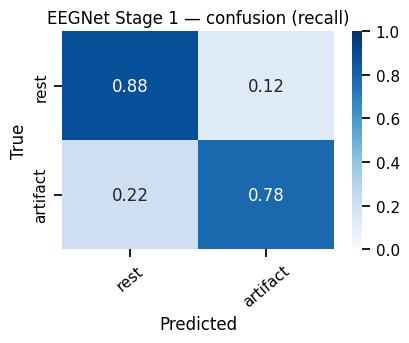

In [10]:
# ---- Stage 1: artifact vs rest ----
true_l1_all = np.array(["rest" if t == "rest" else "artifact" for t in true_fine_all])

s1_acc = accuracy_score(true_l1_all, pred_stage1_all)
s1_f1 = f1_score(true_l1_all, pred_stage1_all, average="macro")
y_true_bin = (true_l1_all == "artifact").astype(int)
s1_auc = roc_auc_score(y_true_bin, pred_stage1_prob_all)

print("Stage 1 (artifact vs rest) — LOSO aggregate")
print(f"  Accuracy : {s1_acc:.4f}")
print(f"  F1 macro : {s1_f1:.4f}")
print(f"  ROC-AUC  : {s1_auc:.4f}")
print(classification_report(true_l1_all, pred_stage1_all,
                            labels=["rest", "artifact"], digits=3))

s1_cm = confusion_matrix(true_l1_all, pred_stage1_all, labels=["rest", "artifact"])
plot_confusion(s1_cm, ["rest", "artifact"],
               "EEGNet Stage 1 — confusion (recall)",
               "Blues", "eegnet_stage1_confusion.png")

Stage 2 (ocular vs head_muscle) — pooled across folds
  n test windows : 5907
  Accuracy       : 0.8893
  F1 macro       : 0.8886
              precision    recall  f1-score   support

      ocular      0.840     0.963     0.897      2963
 head_muscle      0.956     0.816     0.880      2944

    accuracy                          0.889      5907
   macro avg      0.898     0.889     0.889      5907
weighted avg      0.898     0.889     0.889      5907



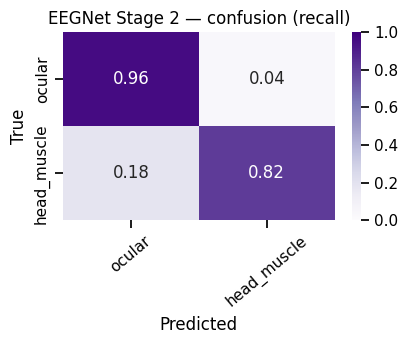

In [11]:
# ---- Stage 2: ocular vs head_muscle (true-label test windows) ----
s2_labels = list(STAGE2_LABELS)
s2_acc = accuracy_score(true_stage2_all, pred_stage2_all)
s2_f1 = f1_score(true_stage2_all, pred_stage2_all, average="macro",
                 labels=s2_labels, zero_division=0)

print("Stage 2 (ocular vs head_muscle) — pooled across folds")
print(f"  n test windows : {len(true_stage2_all)}")
print(f"  Accuracy       : {s2_acc:.4f}")
print(f"  F1 macro       : {s2_f1:.4f}")
print(classification_report(true_stage2_all, pred_stage2_all,
                            labels=s2_labels, digits=3, zero_division=0))

s2_cm = confusion_matrix(true_stage2_all, pred_stage2_all, labels=s2_labels)
plot_confusion(s2_cm, s2_labels, "EEGNet Stage 2 — confusion (recall)",
               "Purples", "eegnet_stage2_confusion.png")


EEGNet Stage 3a (fine ocular) — pooled across folds
  n test windows : 2963
  Accuracy       : 0.7786
  F1 macro       : 0.7791
              precision    recall  f1-score   support

       blink      0.707     0.848     0.771       988
   look_left      0.848     0.743     0.792       988
  look_right      0.807     0.745     0.774       987

    accuracy                          0.779      2963
   macro avg      0.787     0.779     0.779      2963
weighted avg      0.787     0.779     0.779      2963



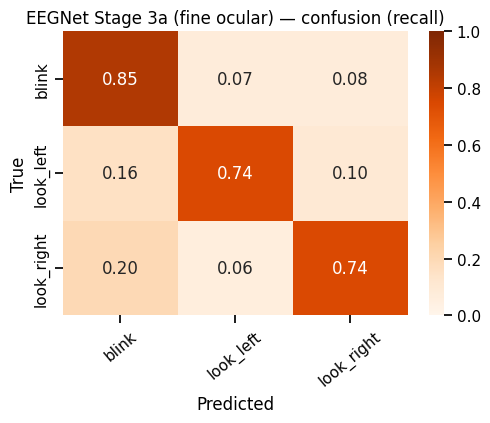


EEGNet Stage 3b (fine head/muscle) — pooled across folds
  n test windows : 2944
  Accuracy       : 0.5934
  F1 macro       : 0.5941
              precision    recall  f1-score   support

      clench      0.611     0.545     0.576       970
  horiz_head      0.669     0.667     0.668       987
   vert_head      0.511     0.567     0.538       987

    accuracy                          0.593      2944
   macro avg      0.597     0.593     0.594      2944
weighted avg      0.597     0.593     0.594      2944



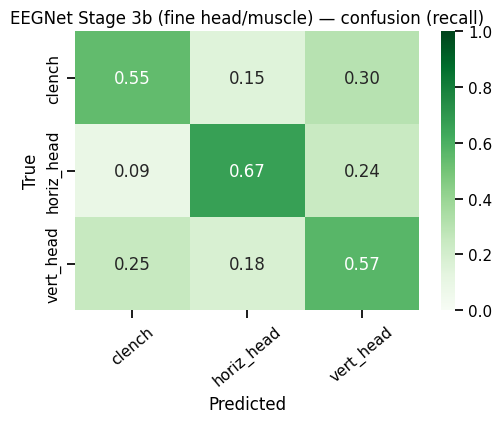

In [12]:
# ---- Stage 3a and 3b: fine label within each coarse group ----
def _evaluate_stage(y_true, y_pred, labels_sorted, title, cmap, fname):
    """Print metrics + confusion matrix for one fine stage; return (acc, f1)."""
    if len(y_true) == 0:
        print(f"{title}: no test windows in this subset.")
        return float("nan"), float("nan")
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average="macro", labels=labels_sorted,
                   zero_division=0)
    print(f"\n{title} — pooled across folds")
    print(f"  n test windows : {len(y_true)}")
    print(f"  Accuracy       : {acc:.4f}")
    print(f"  F1 macro       : {f1m:.4f}")
    print(classification_report(y_true, y_pred, labels=labels_sorted,
                                digits=3, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=labels_sorted)
    plot_confusion(cm, labels_sorted, f"{title} — confusion (recall)", cmap, fname)
    return acc, f1m


s3a_acc, s3a_f1 = _evaluate_stage(
    true_stage3a_all, pred_stage3a_all, sorted(STAGE3A_LABELS),
    "EEGNet Stage 3a (fine ocular)", "Oranges", "eegnet_stage3a_confusion.png")
s3b_acc, s3b_f1 = _evaluate_stage(
    true_stage3b_all, pred_stage3b_all, sorted(STAGE3B_LABELS),
    "EEGNet Stage 3b (fine head/muscle)", "Greens", "eegnet_stage3b_confusion.png")

Chained EEGNet — accuracy 0.6835  F1 macro 0.5711

Chained pipeline classification report:
              precision    recall  f1-score   support

       blink      0.369     0.346     0.357       988
      clench      0.570     0.487     0.525       970
  horiz_head      0.557     0.376     0.449       987
   look_left      0.713     0.645     0.677       988
  look_right      0.690     0.638     0.663       987
        rest      0.792     0.879     0.833      5511
   vert_head      0.473     0.515     0.493       987

    accuracy                          0.683     11418
   macro avg      0.595     0.555     0.571     11418
weighted avg      0.673     0.683     0.675     11418



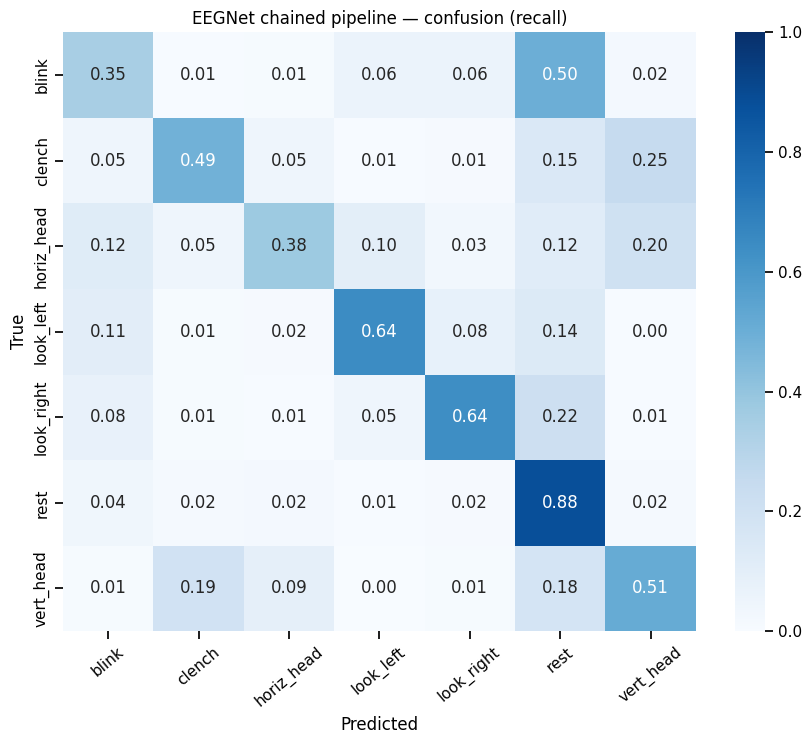

In [13]:
# ---- Chained pipeline, end-to-end (7-class) ----
all_fine_labels = sorted(set(true_fine_all.tolist()) | {"rest"})

chain_acc = accuracy_score(true_fine_all, pred_chain_all)
chain_f1 = f1_score(true_fine_all, pred_chain_all, average="macro",
                    labels=all_fine_labels, zero_division=0)

print(f"Chained EEGNet — accuracy {chain_acc:.4f}  F1 macro {chain_f1:.4f}")
print("\nChained pipeline classification report:")
print(classification_report(true_fine_all, pred_chain_all,
                            labels=all_fine_labels, digits=3, zero_division=0))

chain_cm = confusion_matrix(true_fine_all, pred_chain_all, labels=all_fine_labels)
plot_confusion(chain_cm, all_fine_labels,
               "EEGNet chained pipeline — confusion (recall)",
               "Blues", "eegnet_chained_confusion.png")

## Section 7 — Results summary

In [14]:
# ---- Model comparison (LOSO aggregate) ----
# Thresholding and RF chained come from CONFIG constants so the three approaches
# (thresholding, Random Forest, XGBoost) sit side by side.
comparison_df = pd.DataFrame([
    {"model": "Thresholding (binary)",
     "accuracy": CONFIG["THRESHOLDING_ACC"], "f1_macro": CONFIG["THRESHOLDING_F1"],
     "notes": "binary only; rules fitted on training rest"},
    {"model": "RF chained (03_RandomForest)",
     "accuracy": CONFIG["RF_CHAINED_ACC"], "f1_macro": CONFIG["RF_CHAINED_F1"],
     "notes": "Random Forest hierarchical pipeline"},
    {"model": "Chained XGBoost (7-class)",
     "accuracy": CONFIG["XGB_CHAINED_ACC"], "f1_macro": CONFIG["XGB_CHAINED_F1"],
     "notes": "Chained XGBoost, balanced train"},
    {"model": "Stage 1 only",
     "accuracy": s1_acc, "f1_macro": s1_f1,
     "notes": f"EEGNet binary; ROC-AUC={s1_auc:.4f}"},
    {"model": "Stage 2",
     "accuracy": s2_acc, "f1_macro": s2_f1,
     "notes": "ocular vs head_muscle (true-label test windows)"},
    {"model": "Stage 3a (ocular)",
     "accuracy": s3a_acc, "f1_macro": s3a_f1,
     "notes": "blink / look_left / look_right"},
    {"model": "Stage 3b (head/musc)",
     "accuracy": s3b_acc, "f1_macro": s3b_f1,
     "notes": "horiz_head / vert_head / clench"},
    {"model": "Chained EEGNet",
     "accuracy": chain_acc, "f1_macro": chain_f1,
     "notes": "Stage1 -> Stage2 -> Stage3a/3b (this notebook)"},
])
print(comparison_df.round(4).to_string(index=False))
comparison_df.to_csv(CONFIG["OUTPUT_DIR"] / "EEGNet_model_comparison.csv", index=False)

                       model  accuracy  f1_macro                                           notes
       Thresholding (binary)    0.7759    0.7706      binary only; rules fitted on training rest
RF chained (03_RandomForest)    0.7259    0.6196             Random Forest hierarchical pipeline
   Chained XGBoost (7-class)    0.7499    0.6576                 Chained XGBoost, balanced train
                Stage 1 only    0.8303    0.8302                   EEGNet binary; ROC-AUC=0.8977
                     Stage 2    0.8893    0.8886 ocular vs head_muscle (true-label test windows)
           Stage 3a (ocular)    0.7786    0.7791                  blink / look_left / look_right
        Stage 3b (head/musc)    0.5934    0.5941                 horiz_head / vert_head / clench
              Chained EEGNet    0.6835    0.5711  Stage1 -> Stage2 -> Stage3a/3b (this notebook)
